# Amazon Product Review Analysis
**SI Lab Project: Semester V, B.Tech CSE (AI & DS), Ramdeobaba University, Nagpur**

Sentiment analysis of Amazon product reviews using statistics (sampling, CLT, confidence interval, hypothesis tests, chi-square, correlation) and machine learning (Naive Bayes, Logistic Regression, Linear SVM), with a Gradio user interface.

**Dataset:** Amazon Reviews Multi (English), Hugging Face port
https://huggingface.co/datasets/SetFit/amazon_reviews_multi_en

**Run all cells from top to bottom.**

## 1. Libraries

In [1]:
!pip install -q gradio

import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from scipy import stats

import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

nltk.download("stopwords")
sns.set_style("whitegrid")
np.random.seed(42)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


## 2. Load the Dataset
The data is downloaded from Hugging Face. The `label` column runs from 0 to 4, so `rating = label + 1` gives the 1 to 5 star rating.

In [2]:
url = "https://huggingface.co/datasets/SetFit/amazon_reviews_multi_en/resolve/main/train.jsonl"
data = pd.read_json(url, lines=True)

# keep only the review text and the rating
df_full = data[["text", "label"]].copy()
df_full.columns = ["review", "rating"]
df_full["rating"] = df_full["rating"] + 1

# use 60000 random reviews as our "population"
if len(df_full) > 60000:
    df_full = df_full.sample(n=60000, random_state=42).reset_index(drop=True)

df_full.head()

,review,rating
0,Not strong enough to run a small 120v vacuum c...,3
1,"The leg openings are a little small, but other...",2
2,Really cute mug. I would have given 5 stars if...,4
3,Well it’s looks and feels okay but it most cer...,2
4,"Very, very thin, you can bend them with you fi...",1


## 3. Data Exploration

In [3]:
print("Shape:", df_full.shape)
print("Missing values:", df_full.isnull().sum().sum())
print("Duplicate rows:", df_full.duplicated().sum())
df_full.describe()

Shape: (60000, 2)
Missing values: 0
Duplicate rows: 59


,rating
count,60000.000000
mean,3.009417
std,1.417014
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,5.000000


## 4. Preprocessing and Sentiment Labels
Rating 1-2 = Negative, 3 = Neutral, 4-5 = Positive.

In [4]:
# remove duplicates and empty rows
df_full = df_full.drop_duplicates().dropna().reset_index(drop=True)

# stop words, but keep negative words like "not" because they change the meaning
stop_words = set(stopwords.words("english"))
for w in ["no", "not", "nor", "never", "don", "didn", "doesn", "isn", "wasn"]:
    stop_words.discard(w)

def clean_text(text):
    text = str(text).lower()                    # small letters
    text = re.sub(r"http\S+", " ", text)        # remove links
    text = re.sub(r"[^a-z\s]", " ", text)       # keep only letters
    words = text.split()
    words = [w for w in words if w not in stop_words]
    return " ".join(words)

def to_sentiment(rating):
    if rating <= 2:
        return "Negative"
    elif rating == 3:
        return "Neutral"
    else:
        return "Positive"

df_full["clean_review"] = df_full["review"].apply(clean_text)
df_full = df_full[df_full["clean_review"] != ""].reset_index(drop=True)
df_full["sentiment"] = df_full["rating"].apply(to_sentiment)
df_full["review_length"] = df_full["review"].str.split().str.len()

order = ["Negative", "Neutral", "Positive"]
print("Records after cleaning:", len(df_full))
df_full[["review", "clean_review", "rating", "sentiment"]].head()

Records after cleaning: 59941


,review,clean_review,rating,sentiment
0,Not strong enough to run a small 120v vacuum c...,not strong enough run small v vacuum cleaner c...,3,Neutral
1,"The leg openings are a little small, but other...",leg openings little small suit fits nicely hig...,2,Negative
2,Really cute mug. I would have given 5 stars if...,really cute mug would given stars bit bigger,4,Positive
3,Well it’s looks and feels okay but it most cer...,well looks feels okay certainly not pockets li...,2,Negative
4,"Very, very thin, you can bend them with you fi...",thin bend fingers no problem print small decor...,1,Negative


## 5. Stratified Sampling: Sample vs Population
We take the same fraction of reviews from each sentiment class, then compare the sample with the population.

In [5]:
fraction = min(1.0, 30000 / len(df_full))
df = df_full.groupby("sentiment").sample(frac=fraction, random_state=42).reset_index(drop=True)
print("Sample size:", len(df))

compare = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Std Dev", "Variance"],
    "Population": [df_full["rating"].mean(), df_full["rating"].median(),
                   df_full["rating"].std(), df_full["rating"].var()],
    "Sample": [df["rating"].mean(), df["rating"].median(),
               df["rating"].std(), df["rating"].var()],
})
print(compare)

error = abs(df["rating"].mean() - df_full["rating"].mean()) / df_full["rating"].mean() * 100
print("Percentage error in mean:", round(error, 2))

Sample size: 30000
  Statistic  Population    Sample
0      Mean    3.009593  3.010100
1    Median    3.000000  3.000000
2   Std Dev    1.416721  1.415838
3  Variance    2.007099  2.004598
Percentage error in mean: 0.02


## 6. Distributions and Binomial Probability

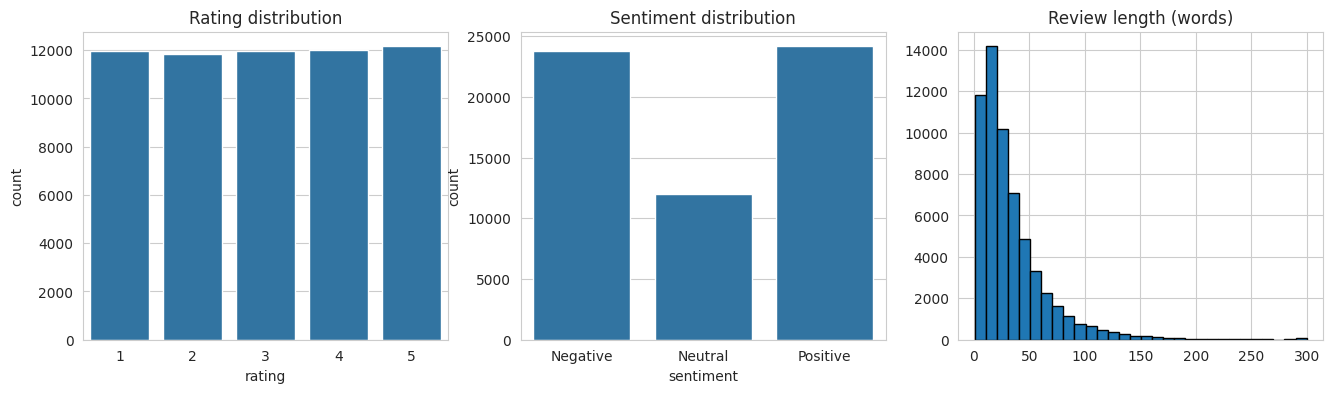

Probability of a positive review: 0.4033


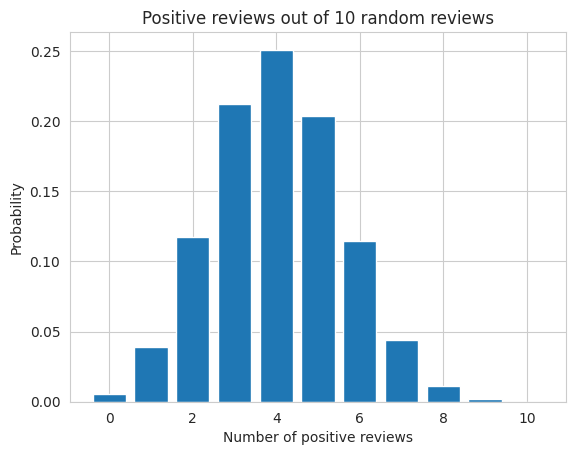

P(exactly 4 positive out of 10): 0.2508


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.countplot(x="rating", data=df_full, ax=axes[0])
axes[0].set_title("Rating distribution")

sns.countplot(x="sentiment", data=df_full, order=order, ax=axes[1])
axes[1].set_title("Sentiment distribution")

axes[2].hist(df_full["review_length"].clip(upper=300), bins=30, edgecolor="black")
axes[2].set_title("Review length (words)")
plt.show()

# Binomial: chance of a positive review
p = (df_full["rating"] >= 4).mean()
print("Probability of a positive review:", round(p, 4))

n_reviews = 10
x = np.arange(0, n_reviews + 1)
plt.bar(x, stats.binom.pmf(x, n_reviews, p))
plt.title("Positive reviews out of 10 random reviews")
plt.xlabel("Number of positive reviews")
plt.ylabel("Probability")
plt.show()
print("P(exactly 4 positive out of 10):", round(stats.binom.pmf(4, n_reviews, p), 4))

## 7. Central Limit Theorem and Standard Error

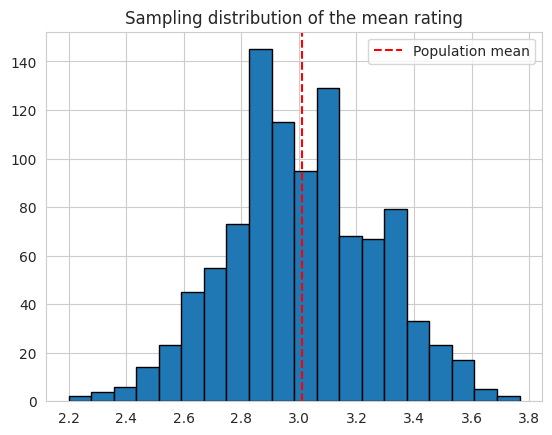

Population mean: 3.0096
Mean of sample means: 3.0108
Theoretical standard error: 0.2587
Observed standard error: 0.2585


In [7]:
population = df_full["rating"].values
sample_size = 30

# take 1000 samples of size 30 and find the mean of each
sample_means = []
for i in range(1000):
    sample = np.random.choice(population, sample_size)
    sample_means.append(sample.mean())
sample_means = np.array(sample_means)

plt.hist(sample_means, bins=20, edgecolor="black")
plt.axvline(population.mean(), color="red", linestyle="--", label="Population mean")
plt.title("Sampling distribution of the mean rating")
plt.legend()
plt.show()

print("Population mean:", round(population.mean(), 4))
print("Mean of sample means:", round(sample_means.mean(), 4))
print("Theoretical standard error:", round(population.std() / np.sqrt(sample_size), 4))
print("Observed standard error:", round(sample_means.std(), 4))

## 8. Confidence Interval and Hypothesis Testing
Steps: state H0 and H1, calculate the test statistic, find the p-value, make a decision.

In [8]:
ratings = df["rating"]
n = len(ratings)
mean = ratings.mean()
std_error = ratings.std() / np.sqrt(n)

# 95% confidence interval
t_value = stats.t.ppf(0.975, df=n - 1)
lower = mean - t_value * std_error
upper = mean + t_value * std_error
print("Sample mean:", round(mean, 4))
print("95% confidence interval:", round(lower, 4), "to", round(upper, 4))

# One sample t-test
print("\nH0: mean rating = 3")
print("H1: mean rating is not 3")
t_stat, p_value_t = stats.ttest_1samp(ratings, popmean=3)
print("t-statistic:", round(t_stat, 4))
print("p-value:", p_value_t)
if p_value_t < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

# One sample z-test (population std taken from the full data)
z_score = (mean - 3) / (population.std() / np.sqrt(n))
p_value_z = 2 * (1 - stats.norm.cdf(abs(z_score)))
print("\nz-score:", round(z_score, 4))
print("p-value:", p_value_z)
if p_value_z < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

Sample mean: 3.0101
95% confidence interval: 2.9941 to 3.0261

H0: mean rating = 3
H1: mean rating is not 3
t-statistic: 1.2356
p-value: 0.2166270758312589
Decision: Fail to reject H0

z-score: 1.2348
p-value: 0.21690001540274206
Decision: Fail to reject H0


## 9. Correlation and Chi-Square Test

Pearson: -0.0339 p = 4.0995832085807314e-09
Spearman: -0.0587 p = 2.574056968489086e-24


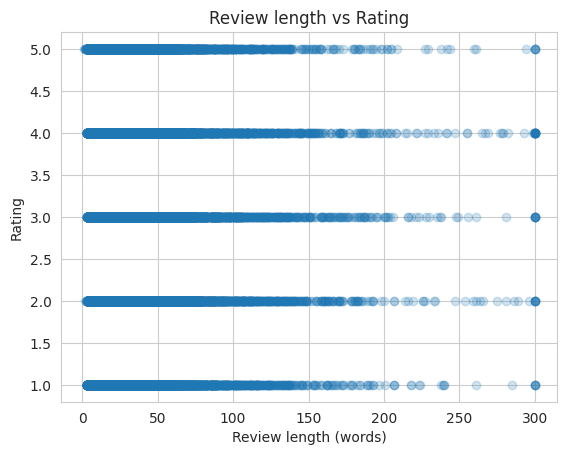


Observed table:
sentiment     Negative  Neutral  Positive
length_group                             
Short             4995     2433      5688
Medium            4502     2264      4300
Long              2415     1293      2110

H0: length group and sentiment are independent
H1: length group and sentiment are not independent
Chi-square: 105.2655 | dof: 4 | p-value: 7.435547592120508e-22
Decision: Reject H0


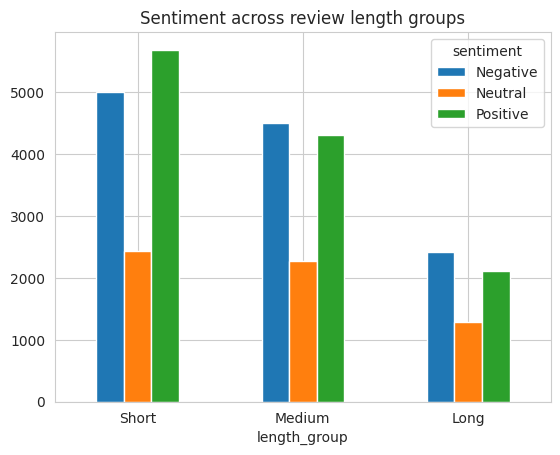

In [9]:
# Correlation between review length and rating
pearson_r, pearson_p = stats.pearsonr(df["review_length"], df["rating"])
spearman_r, spearman_p = stats.spearmanr(df["review_length"], df["rating"])
print("Pearson:", round(pearson_r, 4), "p =", pearson_p)
print("Spearman:", round(spearman_r, 4), "p =", spearman_p)

plt.scatter(df["review_length"].clip(upper=300), df["rating"], alpha=0.2)
plt.xlabel("Review length (words)")
plt.ylabel("Rating")
plt.title("Review length vs Rating")
plt.show()

# Chi-square test: is review length group related to sentiment?
df["length_group"] = pd.cut(df["review_length"], bins=[0, 20, 50, 100000],
                            labels=["Short", "Medium", "Long"])
observed = pd.crosstab(df["length_group"], df["sentiment"])
print("\nObserved table:")
print(observed)

print("\nH0: length group and sentiment are independent")
print("H1: length group and sentiment are not independent")
chi2, p_value, dof, expected = stats.chi2_contingency(observed)
print("Chi-square:", round(chi2, 4), "| dof:", dof, "| p-value:", p_value)
if p_value < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Do not reject H0")

observed.plot(kind="bar")
plt.title("Sentiment across review length groups")
plt.xticks(rotation=0)
plt.show()

## 10. Most Frequent Words per Sentiment

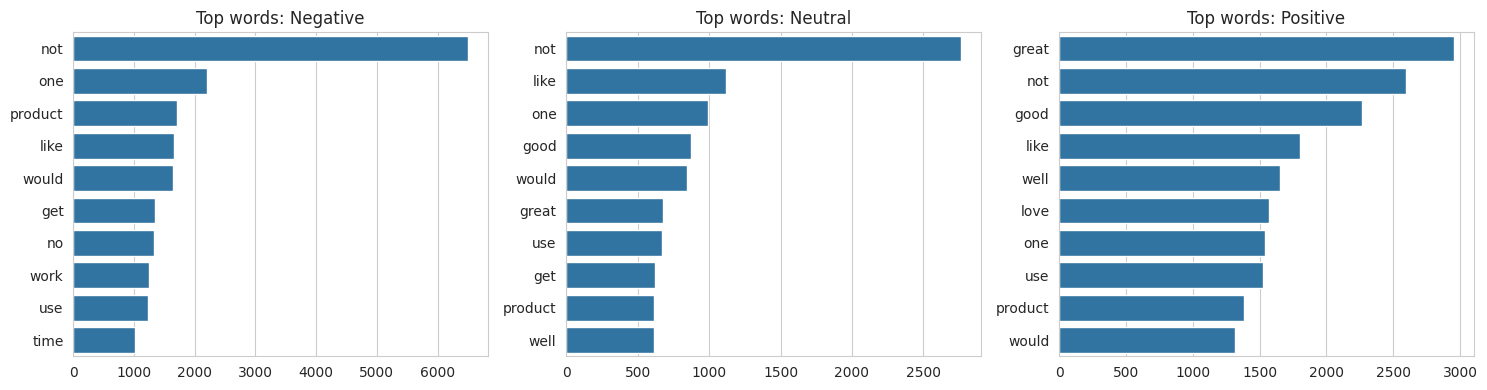

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i in range(3):
    sentiment = order[i]
    words = " ".join(df[df["sentiment"] == sentiment]["clean_review"]).split()
    top = Counter(words).most_common(10)
    sns.barplot(x=[t[1] for t in top], y=[t[0] for t in top], ax=axes[i])
    axes[i].set_title("Top words: " + sentiment)
plt.tight_layout()
plt.show()

## 11. Train/Test Split and TF-IDF
Only the review text is used as input. The rating is NOT used, because the sentiment is made from it (that would be data leakage).

In [11]:
X = df["clean_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# TF-IDF turns text into numbers
tfidf = TfidfVectorizer(max_features=30000, ngram_range=(1, 2), min_df=3)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Train shape:", X_train_tfidf.shape)
print("Test shape:", X_test_tfidf.shape)

Train shape: (24000, 25520)
Test shape: (6000, 25520)


## 12. Train the Models

In [12]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced"),
}

predictions = {}
for name in models:
    models[name].fit(X_train_tfidf, y_train)
    predictions[name] = models[name].predict(X_test_tfidf)
    print(name, "trained")

Naive Bayes trained
Logistic Regression trained
Linear SVM trained


## 13. Compare Models, Pick the Best, Save

                 Model  Accuracy  Precision  Recall  F1-Score  Macro F1
0          Naive Bayes    0.6908     0.6617  0.6908    0.6184    0.5189
1  Logistic Regression    0.6805     0.6888  0.6805    0.6843    0.6350
2           Linear SVM    0.6798     0.6654  0.6798    0.6713    0.6122


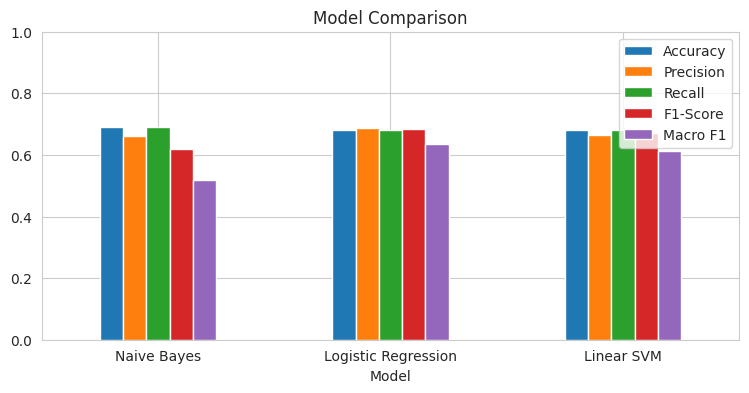

Best model: Logistic Regression


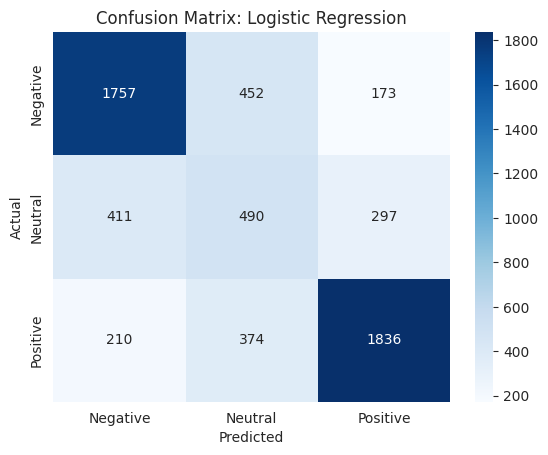

              precision    recall  f1-score   support

    Negative       0.74      0.74      0.74      2382
     Neutral       0.37      0.41      0.39      1198
    Positive       0.80      0.76      0.78      2420

    accuracy                           0.68      6000
   macro avg       0.64      0.64      0.64      6000
weighted avg       0.69      0.68      0.68      6000

Saved best_model.pkl and tfidf_vectorizer.pkl


In [13]:
rows = []
for name in predictions:
    pred = predictions[name]
    rows.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, average="weighted", zero_division=0),
        recall_score(y_test, pred, average="weighted", zero_division=0),
        f1_score(y_test, pred, average="weighted", zero_division=0),
        f1_score(y_test, pred, average="macro", zero_division=0),
    ])
df_results = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision",
                                         "Recall", "F1-Score", "Macro F1"]).round(4)
print(df_results)

df_results.set_index("Model").plot(kind="bar", figsize=(9, 4))
plt.title("Model Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.show()

# best model = highest Macro F1
best_model_name = df_results.loc[df_results["Macro F1"].idxmax(), "Model"]
best_model = models[best_model_name]
best_pred = predictions[best_model_name]
print("Best model:", best_model_name)

# confusion matrix of the best model
labels = ["Negative", "Neutral", "Positive"]
cm = confusion_matrix(y_test, best_pred, labels=labels)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix: " + best_model_name)
plt.show()
print(classification_report(y_test, best_pred, labels=labels, zero_division=0))

# save the model so the UI can use it
joblib.dump(best_model, "best_model.pkl")
joblib.dump(tfidf, "tfidf_vectorizer.pkl")
print("Saved best_model.pkl and tfidf_vectorizer.pkl")

## 14. Gradio User Interface
Three tabs: single review, many reviews at once, and model results.

In [14]:
import gradio as gr

model = joblib.load("best_model.pkl")
vectorizer = joblib.load("tfidf_vectorizer.pkl")

icons = {"Positive": "😊", "Neutral": "😐", "Negative": "😞"}

def get_scores(X):
    # probability of each class (SVM has no predict_proba, so we use softmax)
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)
    d = model.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def predict_one(review):
    cleaned = clean_text(review)
    if cleaned == "":
        return "### Please enter a longer review", {}
    scores = get_scores(vectorizer.transform([cleaned]))[0]
    best = model.classes_[scores.argmax()]
    result = "## " + icons[best] + " " + best + " (" + str(round(scores.max() * 100, 1)) + "% confident)"
    probs = {}
    for c, s in zip(model.classes_, scores):
        probs[icons[c] + " " + c] = float(s)
    return result, probs

def predict_many(text):
    reviews = [r.strip() for r in text.split("\n") if r.strip() != ""]
    if len(reviews) == 0:
        return pd.DataFrame()
    scores = get_scores(vectorizer.transform([clean_text(r) for r in reviews]))
    return pd.DataFrame({
        "Review": reviews,
        "Sentiment": model.classes_[scores.argmax(axis=1)],
        "Confidence %": (scores.max(axis=1) * 100).round(1),
    })

# confusion matrix picture for the results tab
cm_fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix: " + best_model_name)
plt.close(cm_fig)

with gr.Blocks() as demo:
    gr.Markdown("# Amazon Review Sentiment Analyzer")

    with gr.Tab("Single review"):
        review_box = gr.Textbox(lines=5, label="Enter a product review")
        button = gr.Button("Analyze", variant="primary")
        result_text = gr.Markdown()
        result_probs = gr.Label(num_top_classes=3, label="Probabilities")
        gr.Examples(
            ["This product is amazing! Great quality and fast delivery.",
             "It's okay, does the job but nothing special.",
             "Terrible quality. It stopped working after two days."],
            inputs=review_box)
        button.click(predict_one, review_box, [result_text, result_probs])

    with gr.Tab("Many reviews"):
        many_box = gr.Textbox(lines=6, label="One review per line")
        many_button = gr.Button("Analyze all", variant="primary")
        many_table = gr.Dataframe()
        many_button.click(predict_many, many_box, many_table)

    with gr.Tab("Model results"):
        gr.Markdown("Best model: **" + best_model_name + "**")
        gr.Dataframe(value=df_results)
        gr.Plot(value=cm_fig)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b11355be92ae46fddb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 15. Conclusion
Fill this in after running: dataset size, class distribution, statistical findings (confidence interval, test decisions, correlation, chi-square), the model comparison table, the selected model and the reason, and limitations (sarcasm, short reviews, neutral class overlap, English-only vocabulary).